100%|██████████| 170M/170M [25:48<00:00, 110kB/s]


Epoch: 1 Loss: 1.5643396993427325
Epoch: 2 Loss: 1.2281056888725446
Epoch: 3 Loss: 1.0916482229976703
Epoch: 4 Loss: 1.0032689595009054
Epoch: 5 Loss: 0.9356992686800945
Epoch: 6 Loss: 0.8796600083941999
Epoch: 7 Loss: 0.8326928391480994
Epoch: 8 Loss: 0.7845656521180097
Epoch: 9 Loss: 0.745907340513166
Epoch: 10 Loss: 0.7088897027018125
Test Accuracy: 68.91


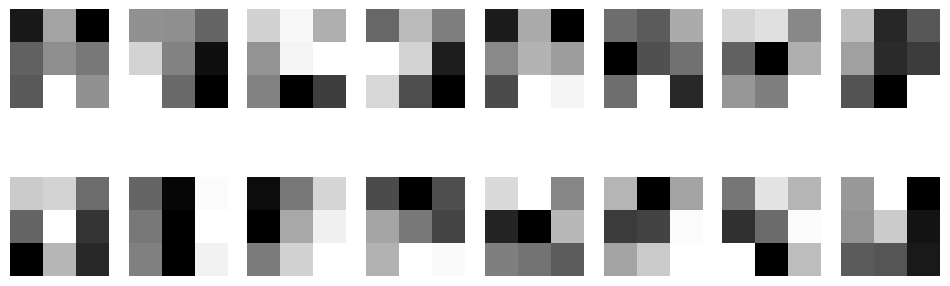

Enter test image index: 200


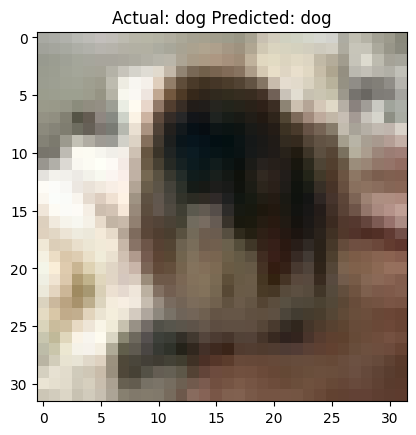

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

transform=transforms.ToTensor()
trainset=torchvision.datasets.CIFAR10(root="./data",train=True,download=True,transform=transform)
testset=torchvision.datasets.CIFAR10(root="./data",train=False,download=True,transform=transform)
trainloader=torch.utils.data.DataLoader(trainset,batch_size=64,shuffle=True)
testloader=torch.utils.data.DataLoader(testset,batch_size=64)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1=nn.Conv2d(3,16,3,padding=1)
        self.conv2=nn.Conv2d(16,32,3,padding=1)
        self.pool=nn.MaxPool2d(2)
        self.fc=nn.Sequential(nn.Linear(32*8*8,128),nn.ReLU(),nn.Linear(128,10))
    def forward(self,x):
        x=self.pool(torch.relu(self.conv1(x)))
        x=self.pool(torch.relu(self.conv2(x)))
        return self.fc(x.view(-1,32*8*8))

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
model=CNN().to(device)
optimizer=optim.Adam(model.parameters(),lr=0.001)
criterion=nn.CrossEntropyLoss()

for epoch in range(10):
    total=0
    for x,y in trainloader:
        x,y=x.to(device),y.to(device)
        optimizer.zero_grad()
        loss=criterion(model(x),y)
        loss.backward()
        optimizer.step()
        total+=loss.item()
    print("Epoch:",epoch+1,"Loss:",total/len(trainloader))

correct=total=0
model.eval()
with torch.no_grad():
    for x,y in testloader:
        pred=model(x.to(device)).argmax(1).cpu()
        correct+=(pred==y).sum().item()
        total+=len(y)
print("Test Accuracy:",100*correct/total)

filters=model.conv1.weight.detach().cpu()
fig,ax=plt.subplots(2,8,figsize=(12,4))
for i,a in enumerate(ax.flat):
    a.imshow(filters[i].mean(0),cmap="gray")
    a.axis("off")
plt.show()

i=int(input("Enter test image index: "))
image,label=testset[i]
pred=model(image.unsqueeze(0).to(device)).argmax(1).item()
plt.imshow(image.permute(1,2,0))
plt.title("Actual: "+trainset.classes[label]+" Predicted: "+trainset.classes[pred])
plt.show()